<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 12 · Parallel workflows, parametric systems, magnetic gauges and shot noise

* `n_jobs=N` distributes energy and parameter sweeps, disorder realisations and k-meshes
  over N worker processes on one node, with one BLAS thread each. On a 40-core node use
  `n_jobs=40` or `export HOPFORGE_NJOBS=40`.
* Kwant-style **value functions** get their parameters at solve time: `params=dict(V=0.3)`.
* `field_gauge(B)` builds Peierls phases for any planar field profile $B(x,y)$.
* Shot noise and the Fano factor come from transmission eigenvalues: $F=\sum\tau(1-\tau)/\sum\tau$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
from hopforge import transport as tr
from hopforge import kpm
import time
print('cores visible:', hf.parallel.available_cores())

cores visible: 2


## 1. Parallel energy sweep (results are identical to serial)

serial 0.62s   parallel 0.17s   identical: True


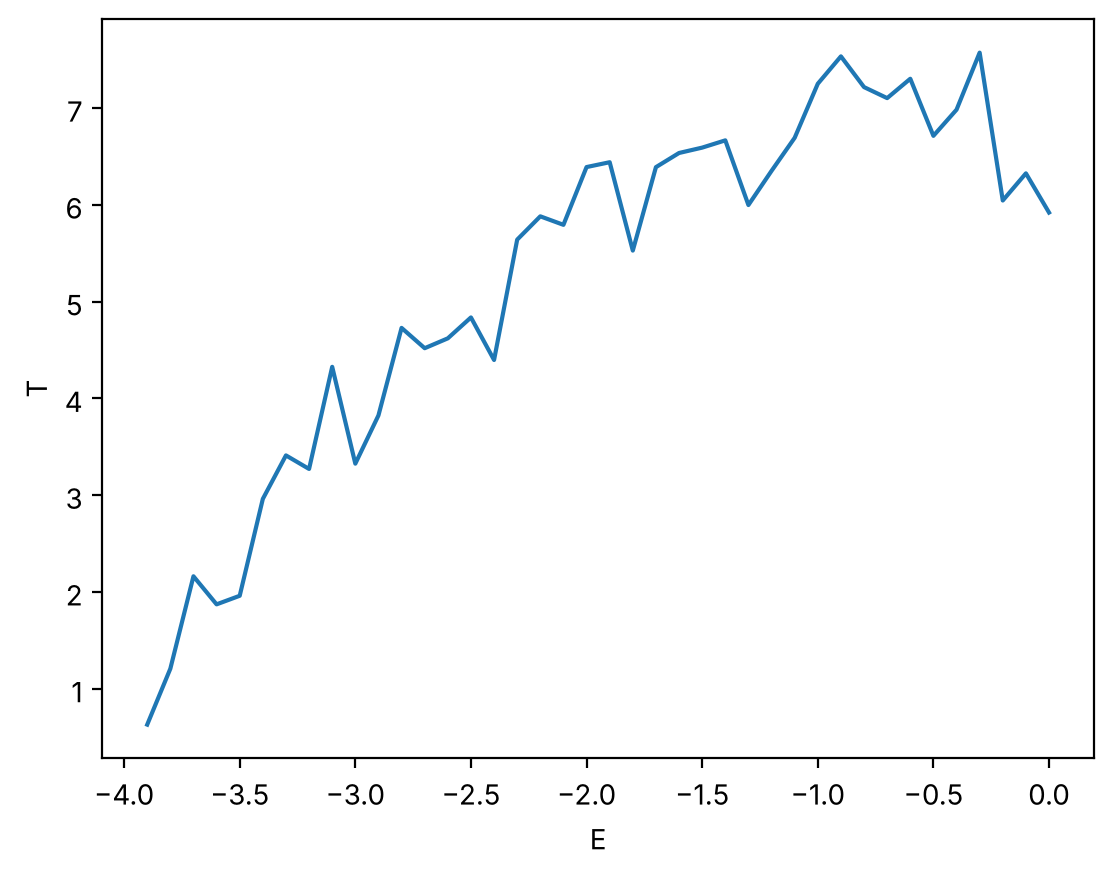

In [2]:
s = tr.System(M.square(), lambda r: 0 <= r[0] < 40 and 0 <= r[1] < 20, onsite=tr.anderson(1.0, seed=1))
s.attach_lead((-1, 0)); s.attach_lead((1, 0))
Es = np.linspace(-3.9, 0, 40)
t0 = time.time(); T1 = s.conductance(Es, n_jobs=1); t1 = time.time() - t0
t0 = time.time(); T2 = s.conductance(Es, n_jobs=-1); t2 = time.time() - t0
print(f"serial {t1:.2f}s   parallel {t2:.2f}s   identical: {np.allclose(T1, T2)}")
plt.plot(Es, T2); plt.xlabel("E"); plt.ylabel("T");

On a 40-core Ibex/Shaheen node a SLURM script looks like `examples/slurm_40cores.sh`:

In [3]:
print(open('../examples/slurm_40cores.sh').read())

#!/bin/bash
#SBATCH --job-name=hopforge
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=40
#SBATCH --time=02:00:00
#SBATCH --output=hopforge_%j.out

# hopforge parallelises over the cores of ONE node with worker processes.
# Each worker uses one BLAS thread; the parent process too.
export HOPFORGE_NJOBS=${SLURM_CPUS_PER_TASK}
export OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 MKL_NUM_THREADS=1

module load python   # adapt to your cluster (Ibex / Shaheen)
python examples/parallel_conductance.py



## 2. Parameters at solve time: a gate-defined barrier

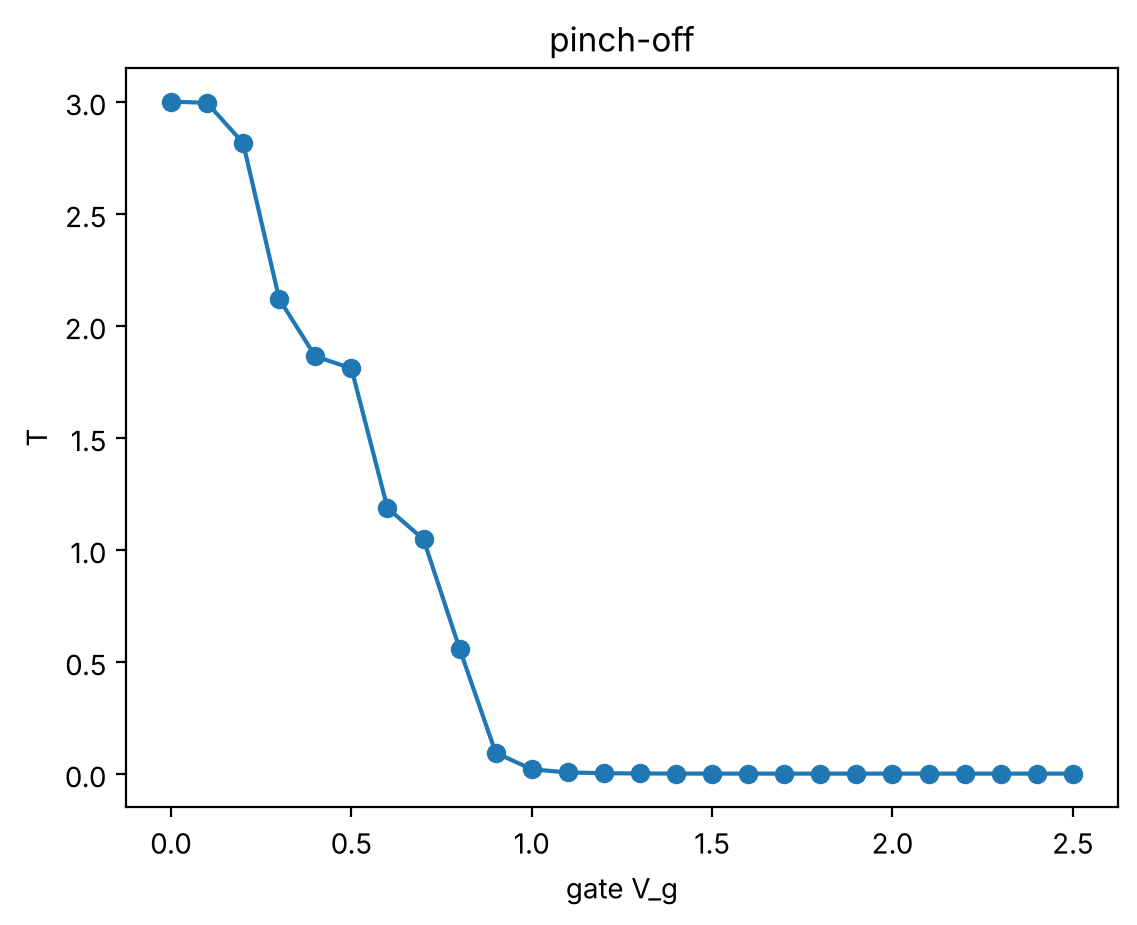

In [4]:
gate = lambda r, name, Vg, w=4: Vg if abs(r[0] - 20) < w else 0.0
g = tr.System(M.square(), lambda r: 0 <= r[0] < 40 and 0 <= r[1] < 10, onsite=gate)
g.attach_lead((-1, 0)); g.attach_lead((1, 0))
Vgs = np.linspace(0, 2.5, 26)
res = tr.sweep(g, lambda S: S.transmission(1, 0), energies=[-3.0], params_list=[dict(Vg=v) for v in Vgs], n_jobs=-1)
plt.plot(Vgs, np.array(res).ravel(), "o-"); plt.xlabel("gate V_g"); plt.ylabel("T"); plt.title("pinch-off");

## 3. Spectrum of the closed system versus a parameter

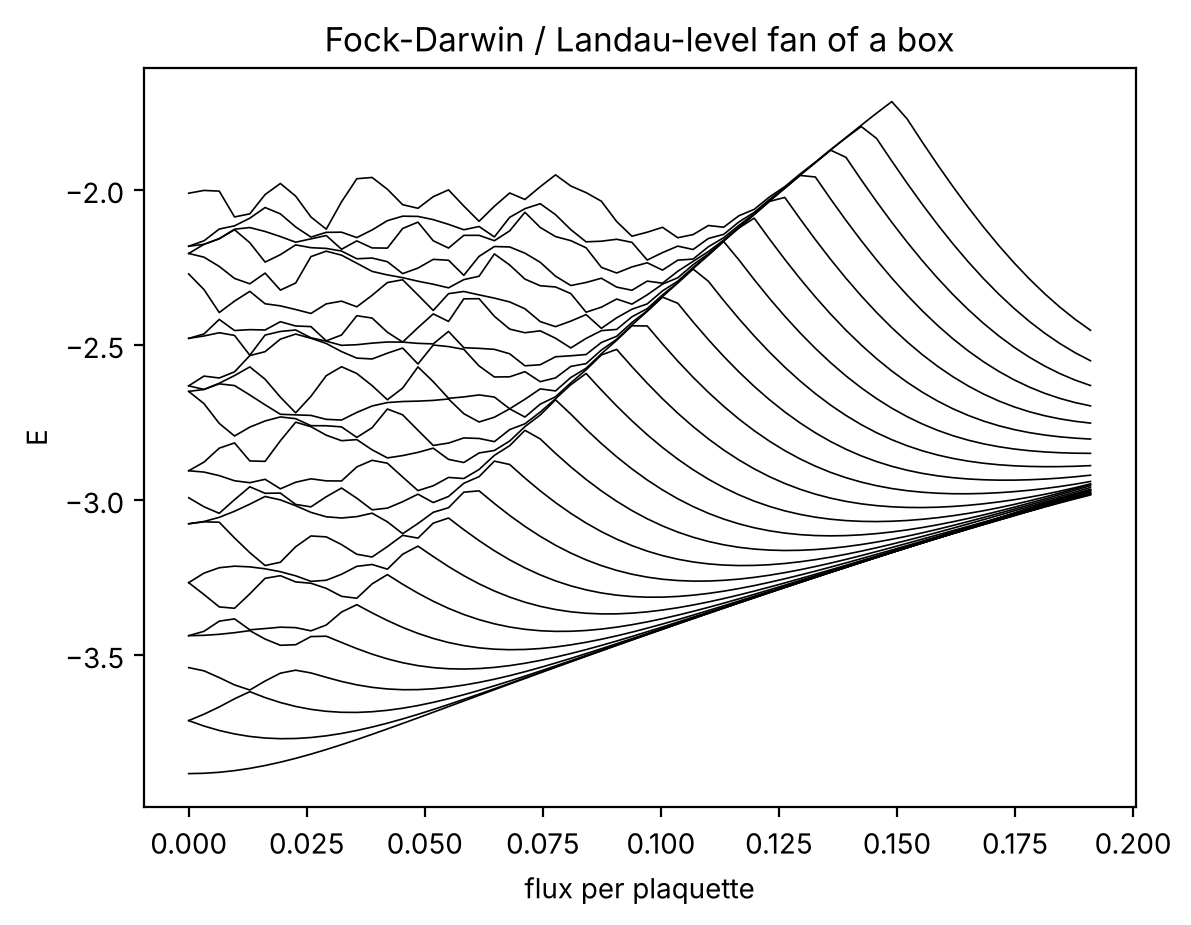

In [5]:
box = tr.System(M.square(), lambda r: 0 <= r[0] < 12 and 0 <= r[1] < 12,
                peierls=tr.field_gauge(lambda x, y, B: B, "x"))
Bs = np.linspace(0, 1.2, 60)
spec = tr.spectrum(box, [dict(B=b) for b in Bs], n_jobs=-1)
for n in range(25): plt.plot(Bs / (2*np.pi), [e[n] for e in spec], "k", lw=0.6)
plt.xlabel("flux per plaquette"); plt.ylabel("E"); plt.title("Fock-Darwin / Landau-level fan of a box");

## 4. Arbitrary magnetic-field profiles: a magnetic barrier

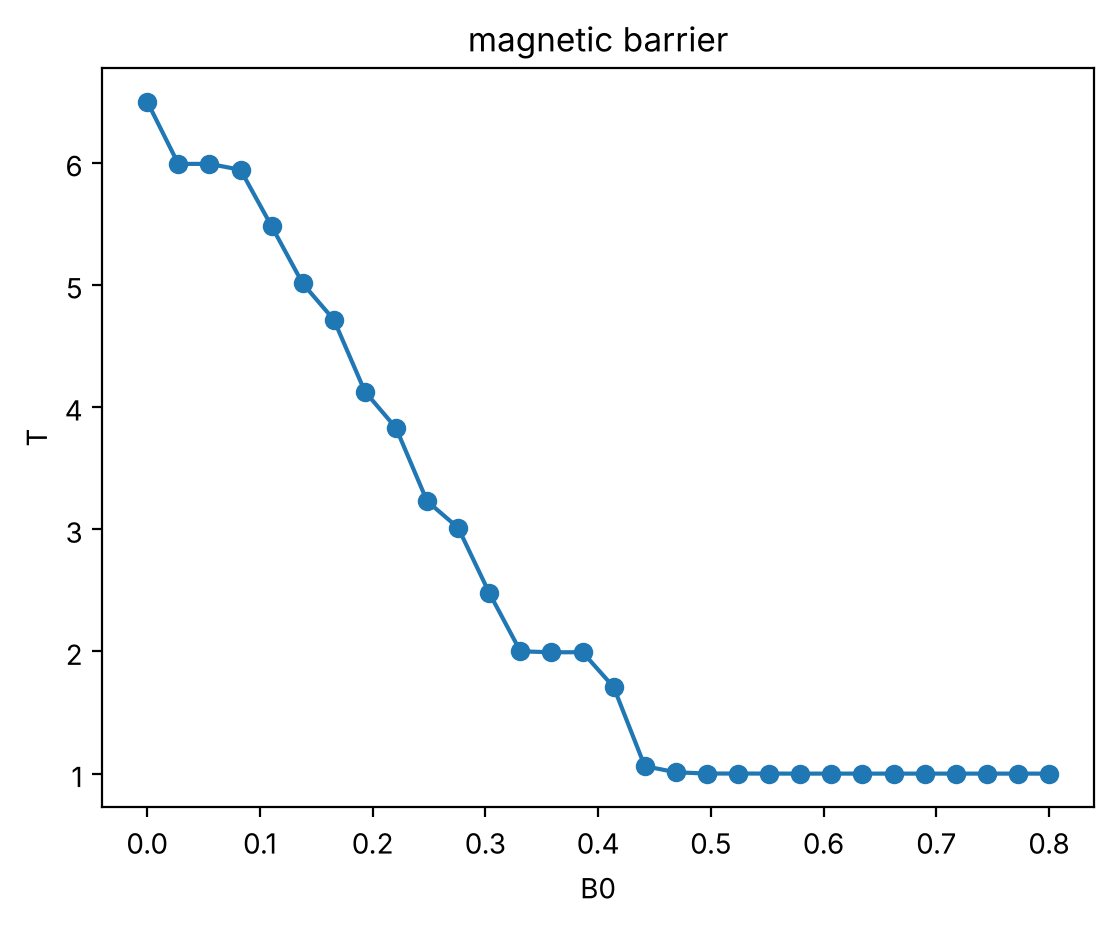

In [6]:
Bprof = lambda x, y, B0: B0 * np.exp(-((x - 30) / 4)**2)          # localised field stripe
mb = tr.System(M.square(), lambda r: 0 <= r[0] < 60 and 0 <= r[1] < 20, peierls=tr.field_gauge(Bprof, "x"))
mb.attach_lead((-1, 0)); mb.attach_lead((1, 0))
B0s = np.linspace(0, 0.8, 30)
T = tr.sweep(mb, lambda S: S.transmission(1, 0), energies=[-3.0], params_list=[dict(B0=b) for b in B0s], n_jobs=-1)
plt.plot(B0s, np.array(T).ravel(), "o-"); plt.xlabel("B0"); plt.ylabel("T"); plt.title("magnetic barrier");

## 5. Shot noise: ballistic, tunnelling and diffusive conductors

ballistic  F = 3.932377236216145e-09
tunnelling F = 0.9957574196106525


diffusive  F = 0.359 +- 0.019   (theory 1/3)


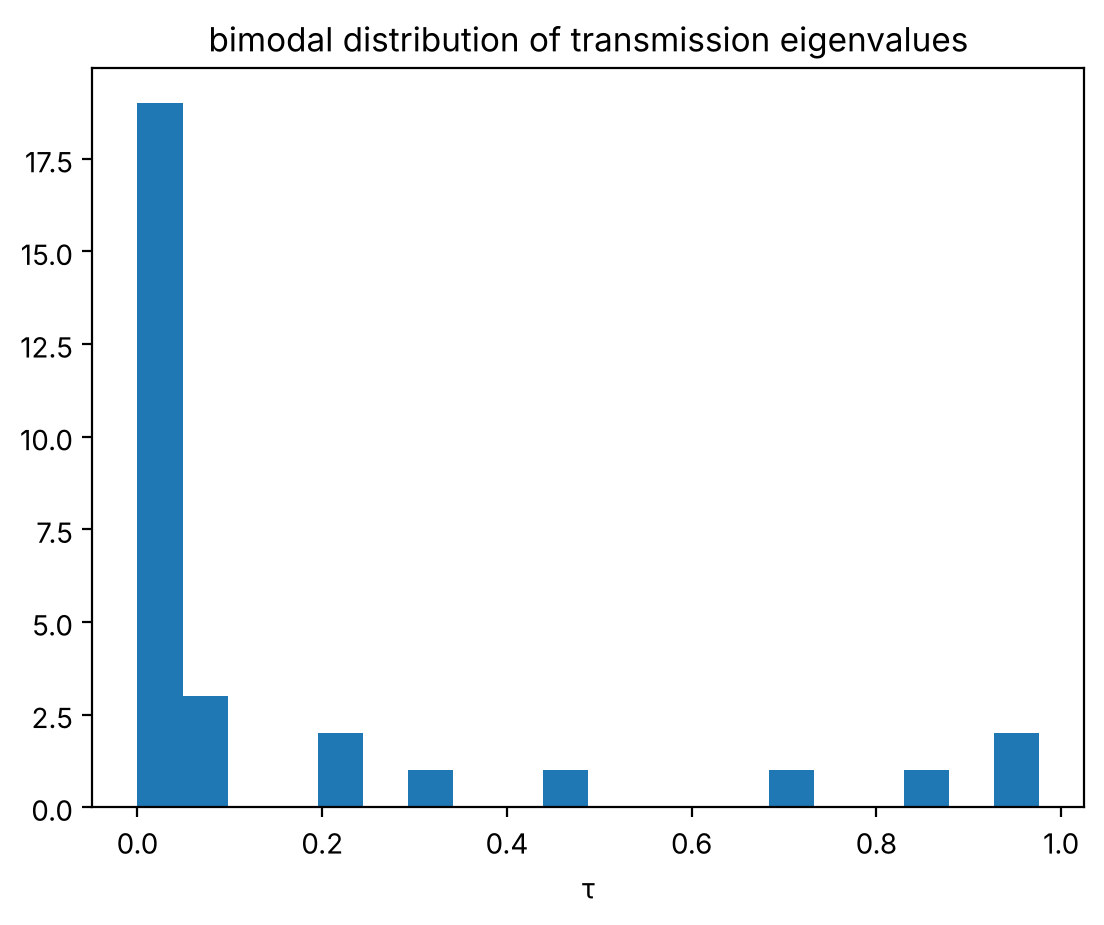

In [7]:
bar = tr.System(M.square(), lambda r: 0 <= r[0] < 20 and 0 <= r[1] < 10,
                onsite=lambda r, n, V: V if 9 <= r[0] < 11 else 0)
bar.attach_lead((-1, 0)); bar.attach_lead((1, 0))
print("ballistic  F =", bar.smatrix(-3.2, params=dict(V=0)).shot_noise()[1])
print("tunnelling F =", bar.smatrix(-3.2, params=dict(V=4)).shot_noise()[1])
def diffusive(seed):
    d = tr.System(M.square(), lambda r: 0 <= r[0] < 60 and 0 <= r[1] < 30, onsite=tr.anderson(1.6, seed=seed))
    d.attach_lead((-1, 0)); d.attach_lead((1, 0)); return d
Fs = hf.parallel.pmap(lambda sd: diffusive(sd).smatrix(-1.0).shot_noise()[1], range(8), n_jobs=-1)
print(f"diffusive  F = {np.mean(Fs):.3f} +- {np.std(Fs)/np.sqrt(len(Fs)):.3f}   (theory 1/3)")
tau = diffusive(0).smatrix(-1.0).transmission_eigenvalues()
plt.hist(tau, bins=20); plt.xlabel("τ"); plt.title("bimodal distribution of transmission eigenvalues");

## 6. Parallel k-space and topology

In [8]:
h = M.haldane()
t0 = time.time(); a = hf.anomalous_hall(h, np.linspace(-3, 3, 61), 300, n_jobs=1).sigma; t1 = time.time() - t0
t0 = time.time(); b = hf.anomalous_hall(h, np.linspace(-3, 3, 61), 300, n_jobs=-1).sigma; t2 = time.time() - t0
print(f"AHC on 90,000 k-points: serial {t1:.2f}s, parallel {t2:.2f}s, identical {np.allclose(a, b)}")
print("FKM Z2 (parallel over the 6 planes):", hf.z2_3d(M.diamond_fkm(), 2, nk=30, nscan=31, n_jobs=-1))

AHC on 90,000 k-points: serial 0.27s, parallel 0.25s, identical True


FKM Z2 (parallel over the 6 planes): (1, 1, 1, 1)


## Exercises
1. Measure the parallel speed-up versus `n_jobs` on your 40-core node.
2. Map T(E, Vg) on a 2D grid with `tr.sweep`.
3. Compute the Fano factor of a chaotic cavity (stadium shape with narrow leads): expect 1/4.

---
## Quiz 12: Parallel, parameters, gauges, noise

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [9]:
quiz = hf.Quiz(12)
quiz.interactive()

In [10]:
quiz.show()

=== Quiz 12: Parallel workflows, parametric systems, magnetic gauges and shot noise ===

Q1. `n_jobs=40` in hopforge distributes work over
   (a) 40 MPI nodes
   (b) 40 threads of one BLAS call
   (c) 40 GPU streams
   (d) 40 worker processes on one node (shared memory)

Q2. Why is each worker restricted to one BLAS/OpenMP thread?
   (a) to save memory only
   (b) BLAS is wrong otherwise
   (c) it is not
   (d) to avoid oversubscription (40 processes x 40 threads on 40 cores)

Q3. Which tasks parallelise trivially?
   (a) reading a file
   (b) one matrix-vector product
   (c) a single sparse LU
   (d) energy sweeps, disorder realisations, k-point chunks, Wilson-loop scans

Q4. `n_jobs=-1` means
   (a) all cores available to the process (respects SLURM affinity)
   (b) one per GPU
   (c) serial
   (d) an error

Q5. Setting HOPFORGE_NJOBS=40 in a SLURM script
   (a) is ignored
   (b) uses MPI
   (c) sets the default n_jobs for every parallel function
   (d) starts 40 jobs

Q6. Kwant-styl

In [11]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0